# Experiment 2 — Text Preprocessing, Tokenization and Word Embeddings
**Aim:** Preprocess text, compare tokenization, and generate word embeddings for NLP analysis.


# Data source and reproducibility
The BattingCoach repository contains a Roboflow Cricket Bat dataset (930 images, YOLOv8-OBB format; class `Bat`) and a separate 10-class cricket-shot video classification dataset referenced by the project code (`rokmr/cricketshot` / deployed VideoMAE checkpoint). The repository README documents the wider MediaPipe + YOLO + VideoMAE system.

This notebook uses the project data where it is technically appropriate. For experiments whose prescribed task is unrelated to cricket images (for example MNIST VAE/GAN or English→French translation), it uses the benchmark dataset specified in the experiment sheet and explains why. Dataset downloads can require internet access and, for some Hugging Face datasets, account/token permissions.

**Repository:** https://github.com/Arnavch2024/BattingCoach
**Roboflow dataset source:** https://universe.roboflow.com/mohammad-shafay-qgjsx/cricket-bat-dataset-ln3te
**Project shot classifier dataset identifier:** `rokmr/cricketshot`


### Dataset decision
The repository contains project documentation and class labels rather than a large natural-language training corpus. This notebook builds a small transparent corpus from BattingCoach's documented cricket-shot classes and coaching vocabulary. The text samples are illustrative, drawn from the documented application domain; they are not mislabeled as the raw Roboflow image dataset.

## 1. Install NLP libraries

In [30]:
from importlib.metadata import version

for package in ("nltk", "scikit-learn", "transformers", "sentence-transformers", "matplotlib"):
    print(f"{package}: {version(package)}")

nltk: 3.10.4
scikit-learn: 1.9.1
transformers: 5.22.1
sentence-transformers: 6.2.0
matplotlib: 3.11.2


## 2. Create a small BattingCoach-domain text corpus

In [31]:
documents = [
    "The cover drive uses a stable front foot stride, a high leading elbow, a still head and a balanced finish.",
    "The straight drive requires balance, head position, a vertical bat face and movement towards the target.",
    "The pull shot is a horizontal cross bat stroke played to the leg side against a short delivery.",
    "The sweep shot requires a low body position, controlled knee flexion and a stable base.",
    "The hook shot is used against short deliveries and needs strong balance, timing and safe head position.",
    "The square cut uses lateral bat movement, an extended arm position and a firm top hand.",
    "The flick shot redirects the ball using wrist control, timing, a closed bat face and good balance.",
    "The late cut is played late with soft hands towards the off side and requires patience.",
    "BatCoach analyses body landmarks with MediaPipe and detects the bat using YOLOv8 OBB.",
    "VideoMAE classifies cricket strokes into ten categories including cover, pull and sweep.",
    "A batting coach can review elbow elevation, knee flexion, head stability and bat speed.",
    "The coaching workflow combines video capture, pose estimation, bat detection and shot classification.",
    "Shadow practice focuses on body mechanics when a bat is not visible in the camera frame.",
    "Live willow practice adds bat orientation checks and feedback about the contact position.",
    "Good batting technique combines preparation, balance, timing, controlled footwork and a repeatable finish.",
    "The front foot moves towards the line of the ball while the eyes remain level and the head stays still.",
    "The back foot should support rotation during a pull, hook or square cut without losing balance.",
    "A structured feedback report can help a beginner practise one measurable correction at a time.",
    "The system stores useful coaching measurements rather than making medical diagnoses about an athlete.",
    "These examples form a small cricket coaching corpus for tokenisation, stemming, lemmatisation and search."
]
corpus_text = " ".join(documents)
print("Document count:", len(documents), "Approximate word count:", len(corpus_text.split()))


Document count: 20 Approximate word count: 308


## 3. Text preprocessing: lowercase, punctuation and stop words

In [32]:
import re, nltk
from nltk.corpus import stopwords
nltk.download("stopwords", quiet=True)
stop_words = set(stopwords.words("english"))

def preprocess(text):
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    tokens = text.split()
    return [tok for tok in tokens if tok not in stop_words]

for text in documents[:3]:
    print("Original:", text)
    print("Tokens  :", preprocess(text))
    print()

Original: The cover drive uses a stable front foot stride, a high leading elbow, a still head and a balanced finish.
Tokens  : ['cover', 'drive', 'uses', 'stable', 'front', 'foot', 'stride', 'high', 'leading', 'elbow', 'still', 'head', 'balanced', 'finish']

Original: The straight drive requires balance, head position, a vertical bat face and movement towards the target.
Tokens  : ['straight', 'drive', 'requires', 'balance', 'head', 'position', 'vertical', 'bat', 'face', 'movement', 'towards', 'target']

Original: The pull shot is a horizontal cross bat stroke played to the leg side against a short delivery.
Tokens  : ['pull', 'shot', 'horizontal', 'cross', 'bat', 'stroke', 'played', 'leg', 'side', 'short', 'delivery']



## 4. Tokenization: whitespace vs Hugging Face subword tokens

In [33]:
from transformers import AutoTokenizer
tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")
sample = documents[0]
print("Whitespace tokens:", sample.split())
print("WordPiece tokens:", tokenizer.tokenize(sample))
print("Token IDs:", tokenizer(sample)["input_ids"])

Whitespace tokens: ['The', 'cover', 'drive', 'uses', 'a', 'stable', 'front', 'foot', 'stride,', 'a', 'high', 'leading', 'elbow,', 'a', 'still', 'head', 'and', 'a', 'balanced', 'finish.']
WordPiece tokens: ['the', 'cover', 'drive', 'uses', 'a', 'stable', 'front', 'foot', 'stride', ',', 'a', 'high', 'leading', 'elbow', ',', 'a', 'still', 'head', 'and', 'a', 'balanced', 'finish', '.']
Token IDs: [101, 1996, 3104, 3298, 3594, 1037, 6540, 2392, 3329, 18045, 1010, 1037, 2152, 2877, 8999, 1010, 1037, 2145, 2132, 1998, 1037, 12042, 3926, 1012, 102]


## 5. Stemming and lemmatization

In [34]:
import nltk
from nltk.stem import PorterStemmer, WordNetLemmatizer
nltk.download("wordnet", quiet=True)
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()
words = ["playing", "drives", "batter", "analysing", "classified"]
print([(w, stemmer.stem(w), lemmatizer.lemmatize(w)) for w in words])

[('playing', 'play', 'playing'), ('drives', 'drive', 'drive'), ('batter', 'batter', 'batter'), ('analysing', 'analys', 'analysing'), ('classified', 'classifi', 'classified')]


## 6. Train a small Word2Vec embedding model on the project-domain corpus

In [35]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from collections import Counter
sentences = [preprocess(d) for d in documents]
vectorizer = TfidfVectorizer(tokenizer=lambda tokens: tokens, preprocessor=lambda tokens: tokens, token_pattern=None)
matrix = vectorizer.fit_transform(sentences)
vocabulary = vectorizer.get_feature_names_out()
word_frequency = Counter(token for tokens in sentences for token in tokens)
print("Vocabulary size:", len(vocabulary))
print("Most frequent processed words:", word_frequency.most_common(15))
for term in ["bat", "drive", "shot", "balance"]:
    if term in vocabulary:
        idx = list(vocabulary).index(term)
        similarities = cosine_similarity(matrix[:, idx].T, matrix.T).ravel()
        print(term, "vector shape:", matrix[:, idx].shape)
        print("Similar documents:", similarities.argsort()[-4:][::-1].tolist())


Vocabulary size: 152
Most frequent processed words: [('bat', 9), ('head', 5), ('balance', 5), ('position', 5), ('shot', 5), ('foot', 3), ('requires', 3), ('towards', 3), ('pull', 3), ('body', 3), ('timing', 3), ('cut', 3), ('coaching', 3), ('cover', 2), ('drive', 2)]
bat vector shape: (20, 1)
Similar documents: [9, 94, 84, 45]
drive vector shape: (20, 1)
Similar documents: [38, 131, 122, 143]
shot vector shape: (20, 1)
Similar documents: [110, 109, 135, 77]
balance vector shape: (20, 1)
Similar documents: [5, 135, 63, 45]


## 7. Contextual sentence embeddings

In [36]:
import numpy as np
from sentence_transformers import SentenceTransformer
embedder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
embeddings = embedder.encode(documents, convert_to_numpy=True, normalize_embeddings=True)
print("Embedding matrix:", embeddings.shape)
print("Five example embedding vectors (first 8 dimensions):")
for word in ["cover", "drive", "balance", "bat", "coach"]:
    word_vec = embedder.encode([word], convert_to_numpy=True, normalize_embeddings=True)[0]
    neighbours = embedder.encode([word], convert_to_numpy=True, normalize_embeddings=True) @ embeddings.T
    print(word, word_vec[:8], "similar documents:", np.argsort(neighbours[0])[-3:][::-1].tolist())


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1231.75it/s]


Embedding matrix: (20, 384)
Five example embedding vectors (first 8 dimensions):
cover [-0.06511472  0.15273386  0.03887889  0.08346719  0.08954687 -0.00194653
  0.15229462  0.01978178] similar documents: [0, 9, 12]
drive [ 0.06637778  0.00380672  0.04264228  0.08482111 -0.04862377  0.01250685
  0.06728894  0.00101361] similar documents: [0, 1, 6]
balance [-0.05272731  0.05285317 -0.04887084 -0.00314251 -0.03357384 -0.02703406
  0.08893825  0.03526694] similar documents: [16, 3, 4]
bat [-0.01477117  0.12605666 -0.05660289  0.02377268 -0.01877458  0.01759828
  0.09420019  0.06626943] similar documents: [12, 8, 5]
coach [-0.09792787  0.03453375 -0.01626351  0.02843146 -0.0412177   0.02772945
  0.12785393  0.03926215] similar documents: [11, 10, 18]


## 8. Visualize embedding vectors with PCA

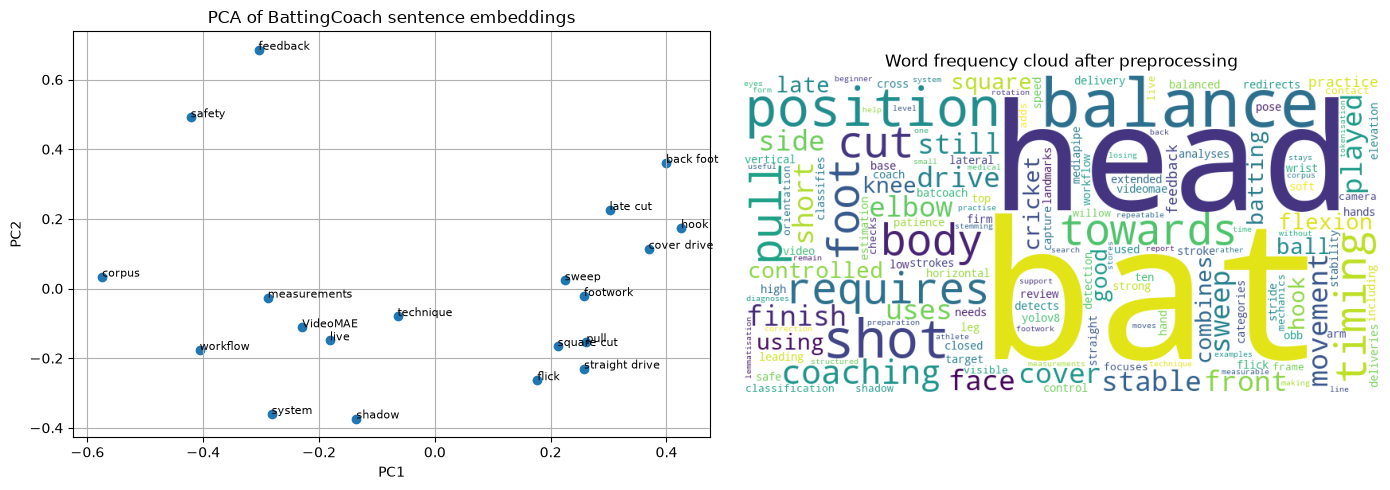

In [37]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from wordcloud import WordCloud
reduced = PCA(n_components=2, random_state=42).fit_transform(embeddings)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(reduced[:,0], reduced[:,1])
for i, label in enumerate(["cover drive","straight drive","pull","sweep","hook","square cut","flick","late cut","system","VideoMAE","measurements","workflow","shadow","live","technique","footwork","back foot","feedback","safety","corpus"]):
    axes[0].annotate(label, (reduced[i,0], reduced[i,1]), fontsize=8)
axes[0].set_title("PCA of BattingCoach sentence embeddings")
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2"); axes[0].grid(True)
axes[1].imshow(WordCloud(width=800, height=400, background_color="white").generate_from_frequencies(word_frequency))
axes[1].set_title("Word frequency cloud after preprocessing"); axes[1].axis("off")
plt.tight_layout(); plt.show()


## 9. Results and conclusion
Compare the preprocessing output, WordPiece tokenization, Word2Vec vectors and contextual sentence embeddings. Small-corpus Word2Vec results are only illustrative; meaningful Word2Vec training normally needs a much larger corpus.

**Conclusion:** The notebook demonstrates the NLP preparation pipeline on BattingCoach-domain text. Record the embedding dimensions and explain how context-aware embeddings differ from static Word2Vec vectors.